In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import joblib
import warnings
warnings.filterwarnings('ignore')

# Set style for matplotlib
sns.set_style("whitegrid")
plt.rcParams['figure.facecolor'] = 'white'

# ====================================
# PHASE 4: VISUALIZATION & ANALYSIS (15 pts)
# ====================================

print("="*70)
print(" PHASE 4: EXPLORATORY DATA ANALYSIS & VISUALIZATION")
print("="*70)

In [ ]:
# ====================================
# STEP 1: LOAD DATA
# ====================================
print("\n[STEP 1] Loading Data...")

try:
    # Load original processed data (before scaling)
    df = pd.read_csv('data/hr_processed.csv')

    # Load original dataset for better visualization
    df_original = pd.read_csv('data/hr_ibm.csv')

    # Load model results (baseline and tuned)
    baseline_results = pd.read_csv('data/baseline_model_comparison.csv')
    model_results = pd.read_csv('data/model_comparison.csv')
    comparison_results = pd.read_csv('data/baseline_vs_tuned_comparison.csv')
    tuning_results = pd.read_csv('data/hyperparameter_tuning_results.csv')
    feature_importance = pd.read_csv('data/feature_importance.csv')
    best_params = pd.read_csv('data/best_hyperparameters.csv')

    print(f"✅ Data loaded successfully")
    print(f"   Original dataset: {df_original.shape}")
    print(f"   Processed dataset: {df.shape}")
    print(f"   Baseline models: {len(baseline_results)}")
    print(f"   Tuned models: {len(model_results)}")

except FileNotFoundError as e:
    print(f"❌ Error: {e}")
    print("   Please run Phase 2 and Phase 3 first!")
    exit()

In [ ]:
# ====================================
# PART A: MATPLOTLIB VISUALIZATIONS
# ====================================

print("\n" + "="*70)
print("PART A: MATPLOTLIB - EXPLORATORY DATA ANALYSIS")
print("="*70)


In [ ]:
# ====================================
# A1: HISTOGRAMS - Distribution Analysis
# ====================================
print("\n[A1] Creating Histograms...")

fig1 = plt.figure(figsize=(20, 12))
gs1 = fig1.add_gridspec(3, 4, hspace=0.4, wspace=0.3)

# Select key numerical features for distribution analysis
numerical_features = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'DistanceFromHome',
                      'YearsInCurrentRole', 'YearsSinceLastPromotion',
                      'YearsWithCurrManager', 'TotalWorkingYears']

for idx, feature in enumerate(numerical_features):
    if feature in df_original.columns:
        row = idx // 4
        col = idx % 4
        ax = fig1.add_subplot(gs1[row, col])

        # Histogram with KDE
        ax.hist(df_original[feature], bins=30, alpha=0.7, color='#3498db',
                edgecolor='black', density=True)

        # Add KDE line
        from scipy.stats import gaussian_kde
        density = gaussian_kde(df_original[feature].dropna())
        xs = np.linspace(df_original[feature].min(), df_original[feature].max(), 200)
        ax.plot(xs, density(xs), 'r-', linewidth=2, label='KDE')

        ax.set_title(f'{feature} Distribution', fontsize=12, fontweight='bold')
        ax.set_xlabel(feature, fontsize=10)
        ax.set_ylabel('Density', fontsize=10)
        ax.legend()
        ax.grid(alpha=0.3)

        # Add statistics
        mean_val = df_original[feature].mean()
        median_val = df_original[feature].median()
        ax.axvline(mean_val, color='green', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.1f}')
        ax.axvline(median_val, color='orange', linestyle='--', linewidth=2, label=f'Median: {median_val:.1f}')

plt.suptitle('EDA: Distribution Analysis - Histograms with KDE',
             fontsize=16, fontweight='bold', y=0.995)
plt.savefig('phase4_histograms.png', dpi=300, bbox_inches='tight')
print("✅ Saved: 'phase4_histograms.png'")

In [ ]:
# ====================================
# A2: BOXPLOTS - Outlier Detection
# ====================================
print("\n[A2] Creating Boxplots...")

fig2 = plt.figure(figsize=(20, 10))
gs2 = fig2.add_gridspec(2, 4, hspace=0.4, wspace=0.3)

for idx, feature in enumerate(numerical_features):
    if feature in df_original.columns:
        row = idx // 4
        col = idx % 4
        ax = fig2.add_subplot(gs2[row, col])

        # Boxplot by Attrition
        if 'Attrition' in df_original.columns:
            df_original.boxplot(column=feature, by='Attrition', ax=ax,
                               patch_artist=True, grid=False)
            ax.set_title(f'{feature} by Attrition', fontsize=12, fontweight='bold')
            ax.set_xlabel('Attrition', fontsize=10)
            ax.set_ylabel(feature, fontsize=10)
            plt.sca(ax)
            plt.xticks([1, 2], ['No', 'Yes'])
        else:
            df_original.boxplot(column=feature, ax=ax, patch_artist=True)
            ax.set_title(f'{feature}', fontsize=12, fontweight='bold')

        ax.grid(alpha=0.3)

plt.suptitle('EDA: Outlier Detection - Boxplots by Target Variable',
             fontsize=16, fontweight='bold', y=0.995)
plt.savefig('phase4_boxplots.png', dpi=300, bbox_inches='tight')
print("✅ Saved: 'phase4_boxplots.png'")

In [ ]:
# ====================================
# A3: CORRELATION MATRIX
# ====================================
print("\n[A3] Creating Correlation Matrix...")

fig3, ax3 = plt.subplots(figsize=(16, 14))

# Select numerical columns for correlation
numerical_df = df_original.select_dtypes(include=[np.number])

# Encode Attrition if it's categorical
if 'Attrition' in df_original.columns and df_original['Attrition'].dtype == 'object':
    numerical_df['Attrition_Encoded'] = df_original['Attrition'].map({'No': 0, 'Yes': 1})

# Calculate correlation matrix
corr_matrix = numerical_df.corr()

# Create heatmap
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1, ax=ax3)

ax3.set_title('Correlation Matrix - All Numerical Features',
              fontsize=16, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('phase4_correlation_matrix.png', dpi=300, bbox_inches='tight')
print("✅ Saved: 'phase4_correlation_matrix.png'")


In [ ]:
# ====================================
# A4: TOP CORRELATIONS WITH TARGET
# ====================================
print("\n[A4] Analyzing Target Correlations...")

if 'Attrition_Encoded' in numerical_df.columns:
    target_corr = numerical_df.corr()['Attrition_Encoded'].abs().sort_values(ascending=False)
    target_corr = target_corr[target_corr.index != 'Attrition_Encoded'].head(15)

    fig4, ax4 = plt.subplots(figsize=(12, 8))
    colors = ['#e74c3c' if x > 0.2 else '#3498db' for x in target_corr.values]
    bars = ax4.barh(target_corr.index, target_corr.values, color=colors, edgecolor='black')

    ax4.set_xlabel('Absolute Correlation with Attrition', fontsize=12, fontweight='bold')
    ax4.set_title('Top 15 Features Correlated with Attrition', fontsize=14, fontweight='bold')
    ax4.invert_yaxis()
    ax4.grid(axis='x', alpha=0.3)

    # Add value labels
    for bar, val in zip(bars, target_corr.values):
        ax4.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontweight='bold', fontsize=9)

    plt.tight_layout()
    plt.savefig('phase4_target_correlation.png', dpi=300, bbox_inches='tight')
    print("✅ Saved: 'phase4_target_correlation.png'")

In [ ]:
# ====================================
# PART B: PLOTLY INTERACTIVE VISUALIZATIONS
# ====================================

print("\n" + "="*70)
print("PART B: PLOTLY - INTERACTIVE VISUALIZATIONS")
print("="*70)

# ====================================
# B1: INTERACTIVE HISTOGRAM (Plotly)
# ====================================
print("\n[B1] Creating Interactive Histograms...")

fig_hist = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Age Distribution', 'Monthly Income Distribution',
                   'Years at Company', 'Distance From Home')
)

features_plotly = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'DistanceFromHome']
positions = [(1,1), (1,2), (2,1), (2,2)]

for feature, (row, col) in zip(features_plotly, positions):
    if feature in df_original.columns:
        fig_hist.add_trace(
            go.Histogram(x=df_original[feature], name=feature,
                        marker_color='#3498db', opacity=0.75,
                        showlegend=False),
            row=row, col=col
        )

fig_hist.update_layout(
    title_text="Interactive Distribution Analysis - Key Features",
    title_font_size=20,
    height=800,
    showlegend=False
)

fig_hist.write_html('phase4_interactive_histograms.html')
print("✅ Saved: 'phase4_interactive_histograms.html'")


In [ ]:
# ====================================
# B2: INTERACTIVE BOXPLOT (Plotly)
# ====================================
print("\n[B2] Creating Interactive Boxplots...")

fig_box = go.Figure()

for feature in ['Age', 'MonthlyIncome', 'YearsAtCompany']:
    if feature in df_original.columns and 'Attrition' in df_original.columns:
        for attrition in df_original['Attrition'].unique():
            data_subset = df_original[df_original['Attrition'] == attrition][feature]
            fig_box.add_trace(go.Box(
                y=data_subset,
                name=f'{feature} - {attrition}',
                boxmean='sd'
            ))

fig_box.update_layout(
    title="Interactive Boxplot Analysis by Attrition Status",
    title_font_size=20,
    yaxis_title="Value",
    height=600,
    showlegend=True
)

fig_box.write_html('phase4_interactive_boxplots.html')
print("✅ Saved: 'phase4_interactive_boxplots.html'")

In [ ]:
# ====================================
# B3: 3D SCATTER PLOT (Plotly)
# ====================================
print("\n[B3] Creating 3D Scatter Plot...")

if all(col in df_original.columns for col in ['Age', 'MonthlyIncome', 'YearsAtCompany', 'Attrition']):
    fig_3d = px.scatter_3d(
        df_original,
        x='Age',
        y='MonthlyIncome',
        z='YearsAtCompany',
        color='Attrition',
        title='3D Feature Space - Age vs Income vs Tenure',
        labels={'Age': 'Age', 'MonthlyIncome': 'Monthly Income', 'YearsAtCompany': 'Years at Company'},
        color_discrete_map={'Yes': '#e74c3c', 'No': '#2ecc71'},
        opacity=0.7,
        height=700
    )

    fig_3d.update_traces(marker=dict(size=5))
    fig_3d.write_html('phase4_3d_scatter.html')
    print("✅ Saved: 'phase4_3d_scatter.html'")

In [ ]:
# ====================================
# B4: INTERACTIVE CORRELATION HEATMAP
# ====================================
print("\n[B4] Creating Interactive Correlation Heatmap...")

# Select top correlated features for better visualization
top_features = target_corr.head(15).index.tolist() + ['Attrition_Encoded']
corr_subset = numerical_df[top_features].corr()

fig_corr = go.Figure(data=go.Heatmap(
    z=corr_subset.values,
    x=corr_subset.columns,
    y=corr_subset.columns,
    colorscale='RdBu',
    zmid=0,
    text=corr_subset.values,
    texttemplate='%{text:.2f}',
    textfont={"size": 8},
    colorbar=dict(title="Correlation")
))

fig_corr.update_layout(
    title="Interactive Correlation Heatmap - Top Features",
    title_font_size=20,
    height=800,
    width=900
)

fig_corr.write_html('phase4_interactive_correlation.html')
print("✅ Saved: 'phase4_interactive_correlation.html'")

 PHASE 4: EXPLORATORY DATA ANALYSIS & VISUALIZATION

[STEP 1] Loading Data...
✅ Data loaded successfully
   Original dataset: (1470, 35)
   Processed dataset: (699, 54)
   Baseline models: 4
   Tuned models: 4

PART A: MATPLOTLIB - EXPLORATORY DATA ANALYSIS

[A1] Creating Histograms...
✅ Saved: 'phase4_histograms.png'

[A2] Creating Boxplots...
✅ Saved: 'phase4_boxplots.png'

[A3] Creating Correlation Matrix...
✅ Saved: 'phase4_correlation_matrix.png'

[A4] Analyzing Target Correlations...
✅ Saved: 'phase4_target_correlation.png'

PART B: PLOTLY - INTERACTIVE VISUALIZATIONS

[B1] Creating Interactive Histograms...
✅ Saved: 'phase4_interactive_histograms.html'

[B2] Creating Interactive Boxplots...
✅ Saved: 'phase4_interactive_boxplots.html'

[B3] Creating 3D Scatter Plot...
✅ Saved: 'phase4_3d_scatter.html'

[B4] Creating Interactive Correlation Heatmap...
✅ Saved: 'phase4_interactive_correlation.html'

[B5] Creating Baseline vs Tuned Comparison Charts...
✅ Saved: 'phase4_baseline_vs_t

ValueError: 
    Invalid element(s) received for the 'size' property of scatter.marker
        Invalid elements include: [-9.065118332175, -12.240683563141701, -20.2370599505]

    The 'size' property is a number and may be specified as:
      - An int or float in the interval [0, inf]
      - A tuple, list, or one-dimensional numpy array of the above

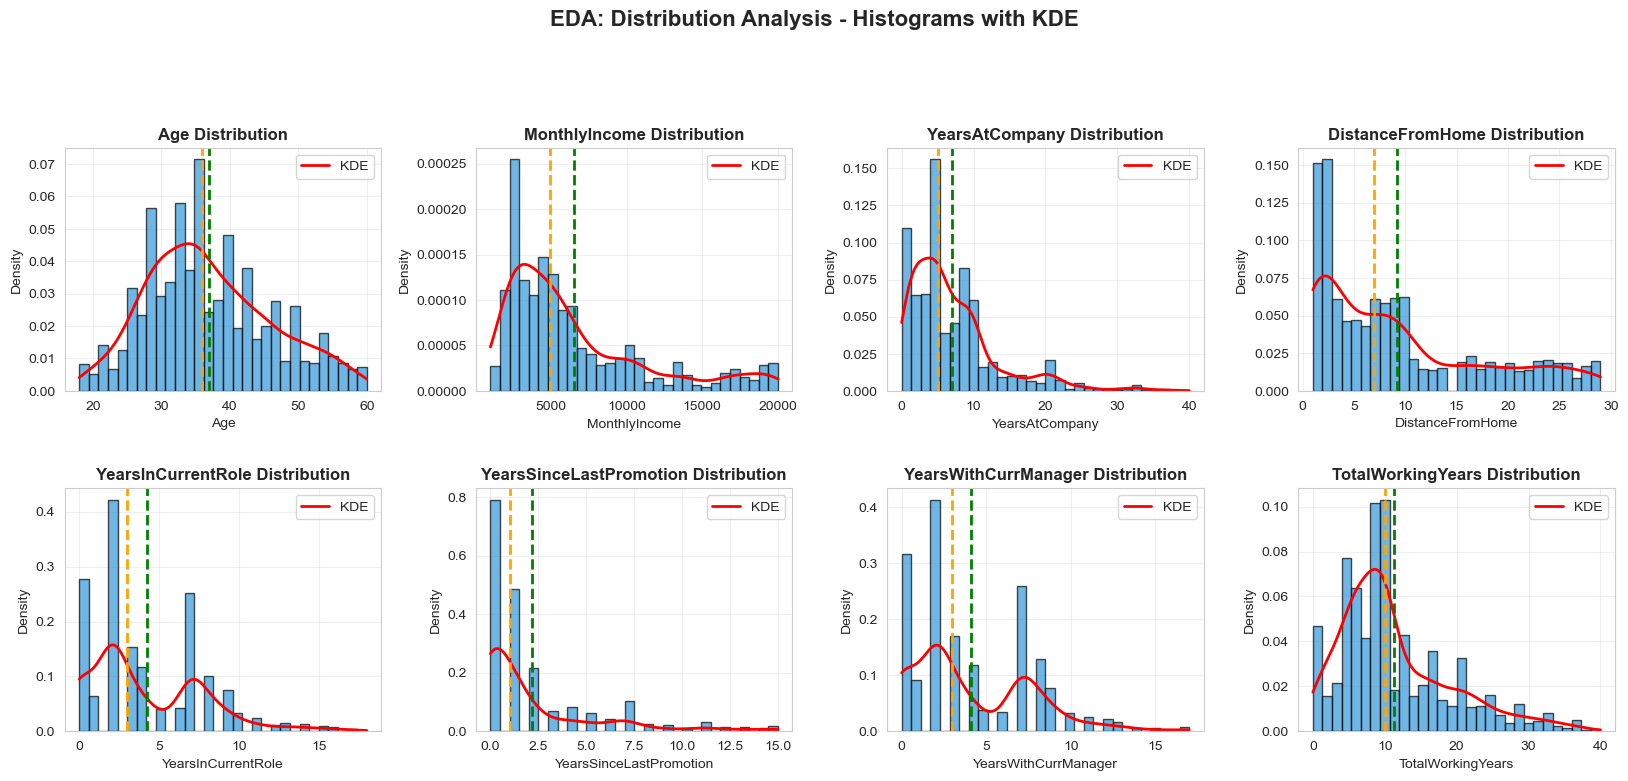

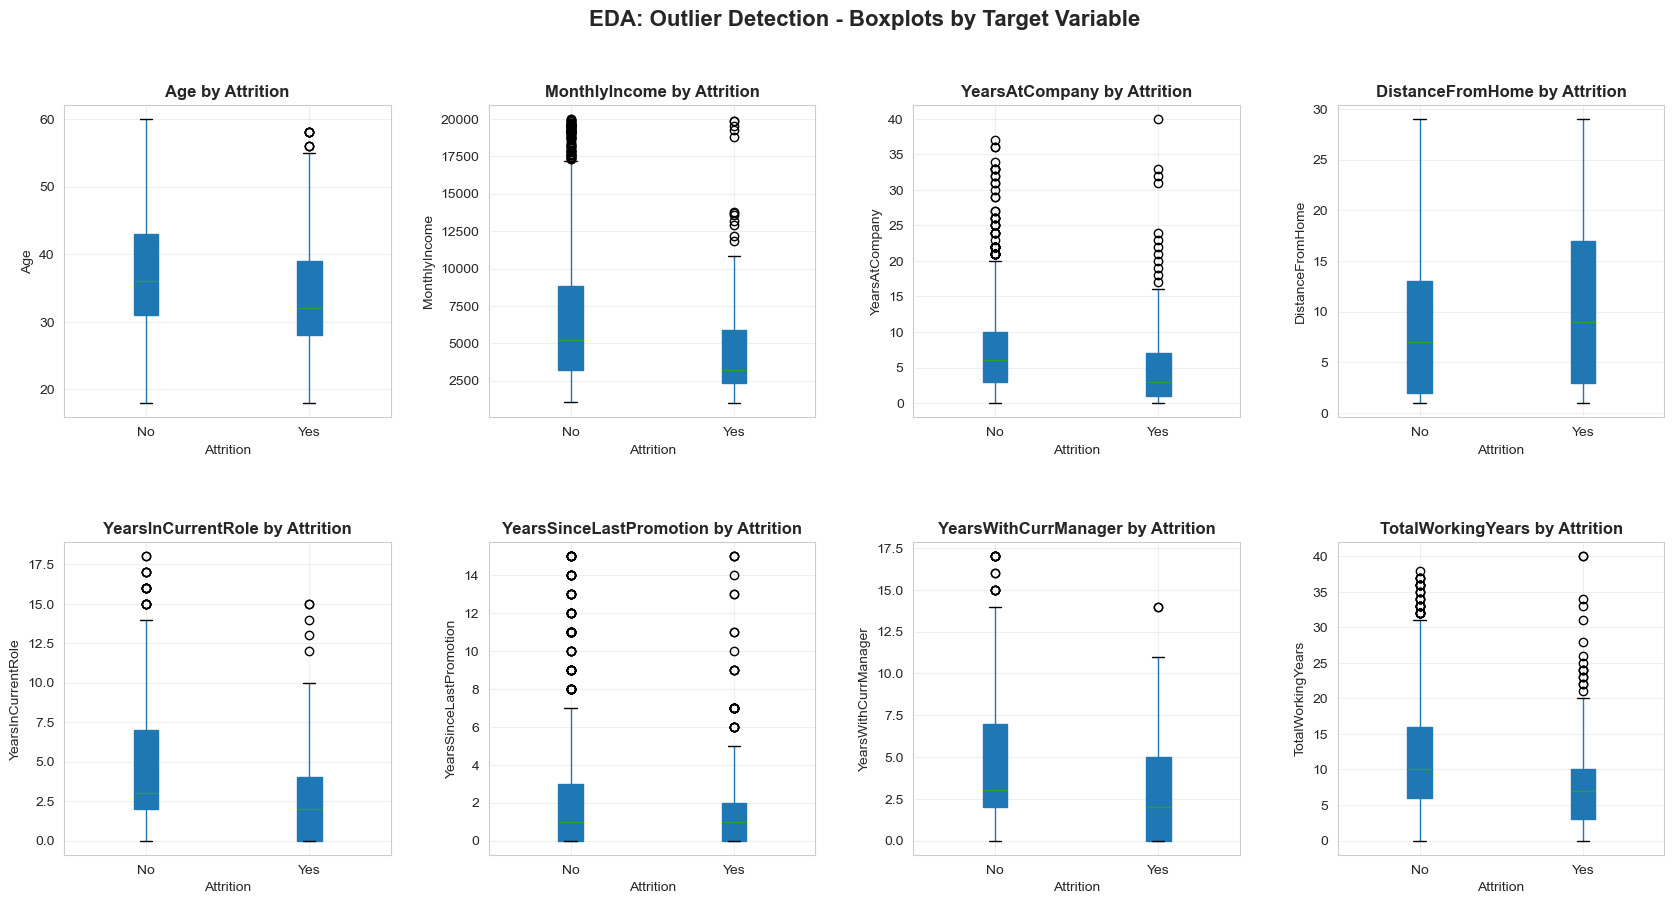

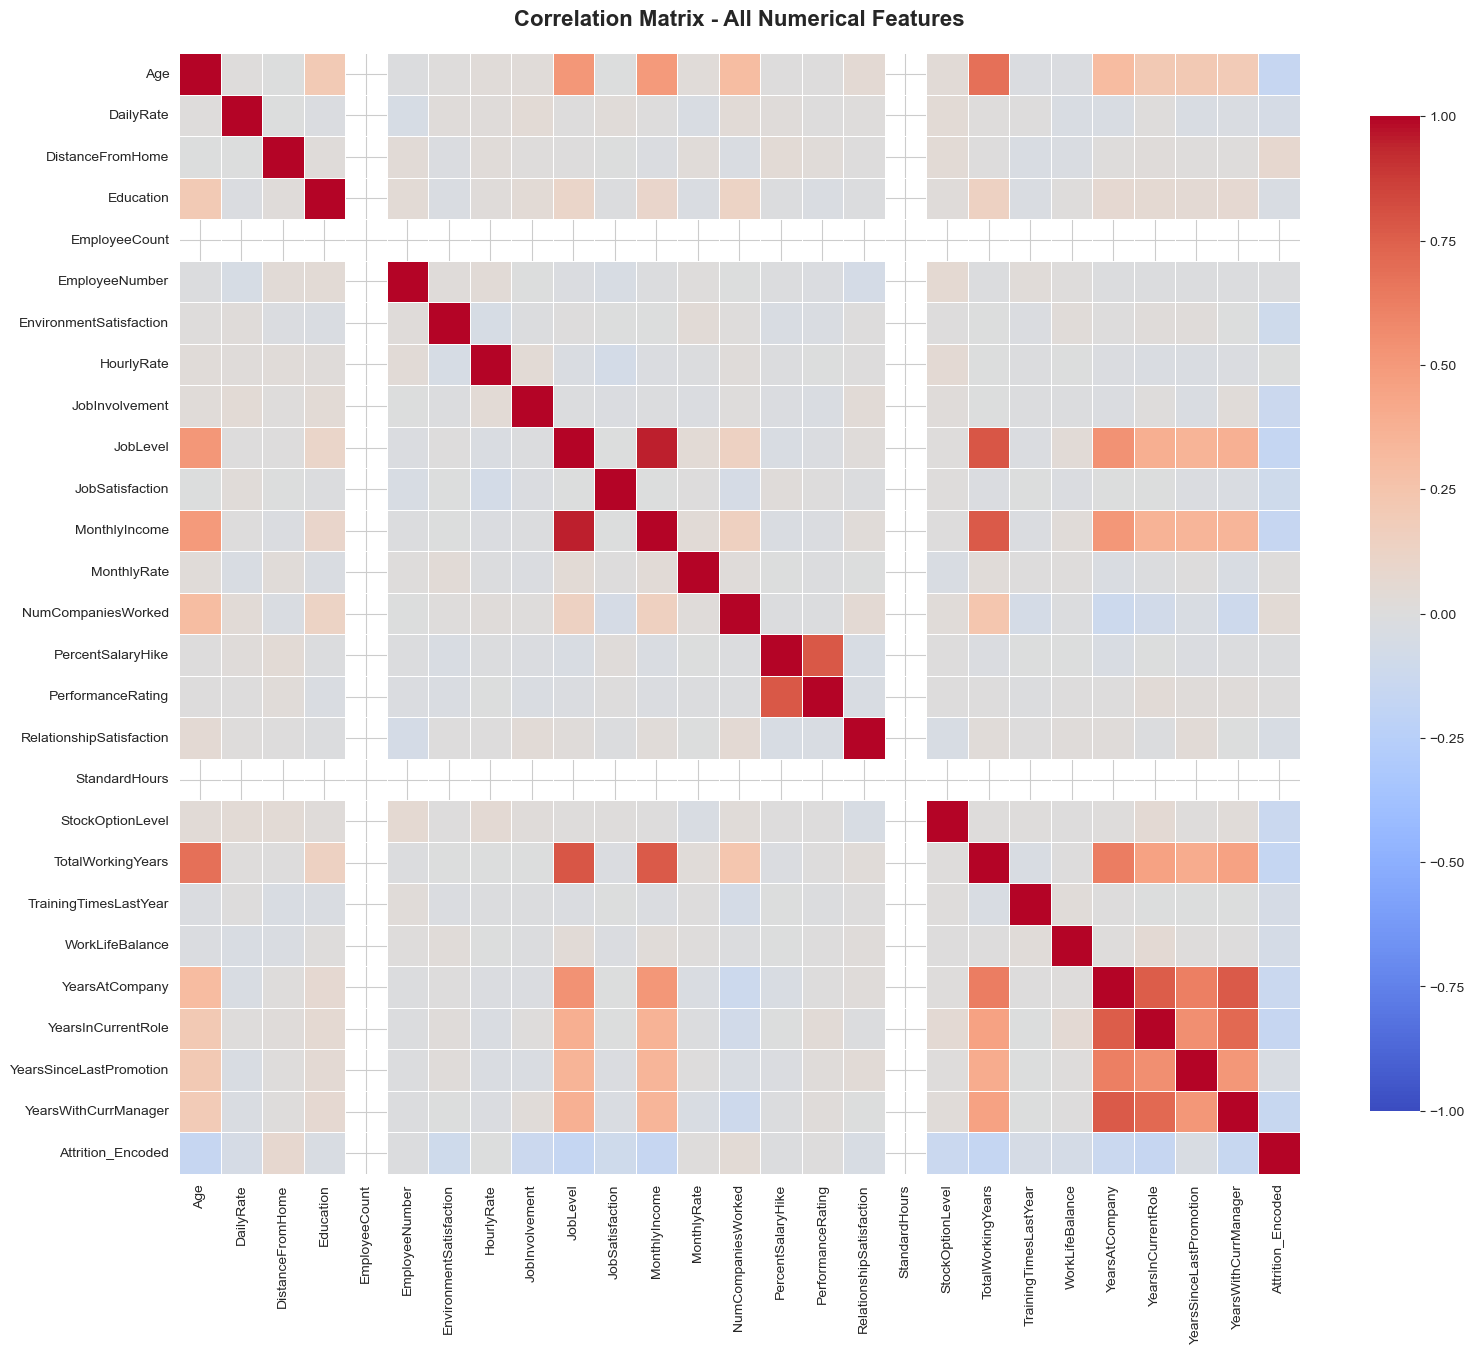

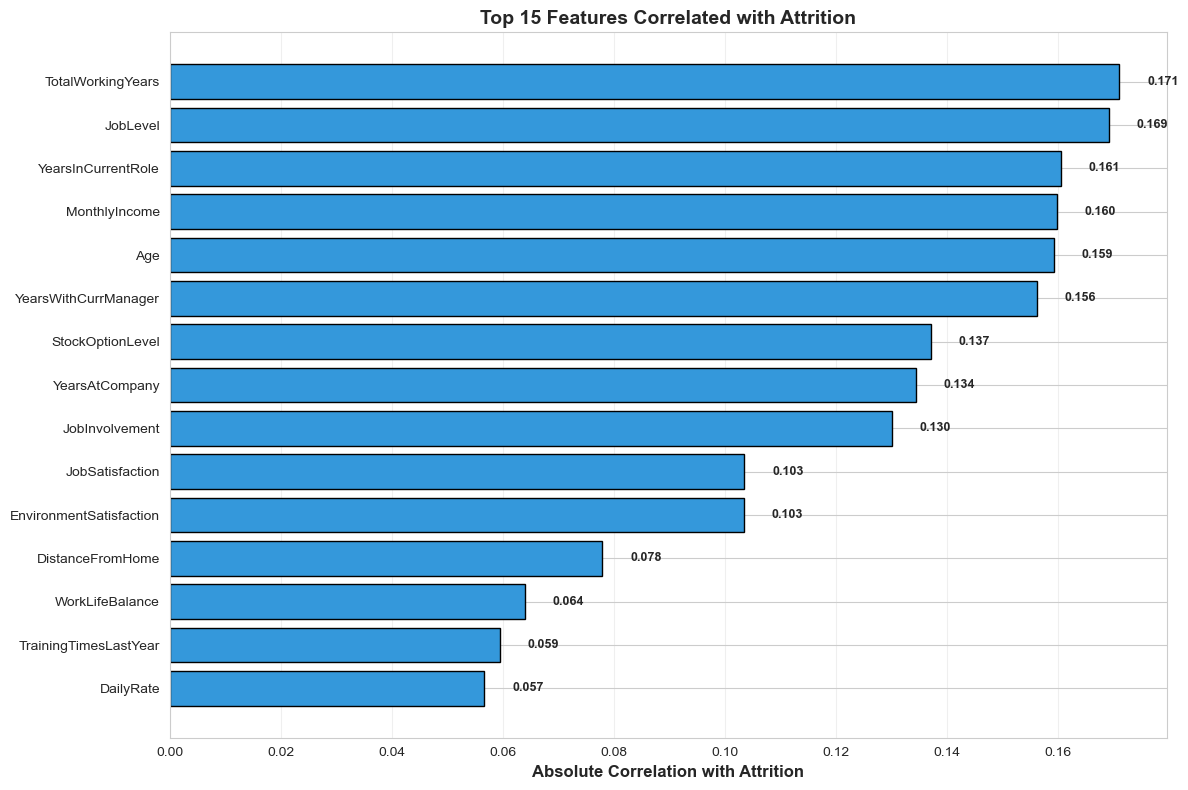

In [1]:
# ====================================
# B5: BASELINE vs TUNED MODEL COMPARISON (INTERACTIVE)
# ====================================
print("\n[B5] Creating Baseline vs Tuned Comparison Charts...")

# Bar chart comparing baseline vs tuned
fig_comparison = go.Figure()

fig_comparison.add_trace(go.Bar(
    name='Baseline',
    x=comparison_results['Model'],
    y=comparison_results['ROC-AUC_Baseline'],
    marker_color='#e74c3c',
    text=comparison_results['ROC-AUC_Baseline'].round(3),
    textposition='outside'
))

fig_comparison.add_trace(go.Bar(
    name='Tuned',
    x=comparison_results['Model'],
    y=comparison_results['ROC-AUC_Tuned'],
    marker_color='#2ecc71',
    text=comparison_results['ROC-AUC_Tuned'].round(3),
    textposition='outside'
))

fig_comparison.update_layout(
    title="Baseline vs Hyperparameter-Tuned Performance Comparison",
    title_font_size=20,
    xaxis_title="Model",
    yaxis_title="ROC-AUC Score",
    barmode='group',
    height=600,
    showlegend=True
)

fig_comparison.write_html('phase4_baseline_vs_tuned_interactive.html')
print("✅ Saved: 'phase4_baseline_vs_tuned_interactive.html'")

# ====================================
# B6: IMPROVEMENT ANALYSIS (INTERACTIVE)
# ====================================
print("\n[B6] Creating Improvement Analysis Chart...")

fig_improvement = go.Figure()

colors_improvement = ['#2ecc71' if x > 0 else '#e74c3c' 
                      for x in comparison_results['Improvement_%']]

fig_improvement.add_trace(go.Bar(
    x=comparison_results['Improvement_%'],
    y=comparison_results['Model'],
    orientation='h',
    marker_color=colors_improvement,
    text=comparison_results['Improvement_%'].round(2).astype(str) + '%',
    textposition='outside'
))

fig_improvement.update_layout(
    title="Performance Improvement from Hyperparameter Tuning",
    title_font_size=20,
    xaxis_title="Improvement (%)",
    yaxis_title="Model",
    height=500
)

fig_improvement.write_html('phase4_improvement_analysis.html')
print("✅ Saved: 'phase4_improvement_analysis.html'")

# ====================================
# B7: MODEL COMPARISON RADAR CHART (BASELINE vs TUNED)
# ====================================
print("\n[B7] Creating Model Comparison Radar Chart...")

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

fig_radar = go.Figure()

# Add baseline models
for idx, row in baseline_results.iterrows():
    fig_radar.add_trace(go.Scatterpolar(
        r=[row['Accuracy'], row['Precision'], row['Recall'], row['F1-Score'], row['ROC-AUC']],
        theta=categories,
        fill='toself',
        name=row['Model'] + ' (Baseline)',
        opacity=0.5,
        line=dict(dash='dash')
    ))

# Add tuned models
for idx, row in model_results.iterrows():
    fig_radar.add_trace(go.Scatterpolar(
        r=[row['Accuracy'], row['Precision'], row['Recall'], row['F1-Score'], row['ROC-AUC']],
        theta=categories,
        fill='toself',
        name=row['Model'] + ' (Tuned)',
        line=dict(width=2)
    ))

fig_radar.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, 1]
        )),
    showlegend=True,
    title="Model Performance Radar: Baseline vs Tuned",
    title_font_size=20,
    height=700
)

fig_radar.write_html('phase4_model_radar_comparison.html')
print("✅ Saved: 'phase4_model_radar_comparison.html'")

# ====================================
# B8: HYPERPARAMETER TUNING RESULTS (INTERACTIVE)
# ====================================
print("\n[B8] Creating Hyperparameter Tuning Analysis...")

fig_tuning = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Tuning Time Analysis', 'Improvement vs Time'),
    specs=[[{'type': 'bar'}, {'type': 'scatter'}]]
)

# Tuning time
fig_tuning.add_trace(
    go.Bar(
        x=tuning_results['Model'],
        y=tuning_results['Tuning_Time'],
        marker_color='#3498db',
        text=tuning_results['Tuning_Time'].round(1),
        textposition='outside',
        name='Tuning Time (s)'
    ),
    row=1, col=1
)

# Improvement vs Time scatter
fig_tuning.add_trace(
    go.Scatter(
        x=tuning_results['Tuning_Time'],
        y=tuning_results['Improvement'],
        mode='markers+text',
        marker=dict(
            size=tuning_results['Improvement'] * 1000,
            color=tuning_results['Improvement'],
            colorscale='RdYlGn',
            showscale=True,
            colorbar=dict(title="Improvement")
        ),
        text=tuning_results['Model'].str.split().str[0],
        textposition='top center',
        name='Improvement'
    ),
    row=1, col=2
)

fig_tuning.update_xaxes(title_text="Model", row=1, col=1)
fig_tuning.update_yaxes(title_text="Time (seconds)", row=1, col=1)
fig_tuning.update_xaxes(title_text="Tuning Time (seconds)", row=1, col=2)
fig_tuning.update_yaxes(title_text="ROC-AUC Improvement", row=1, col=2)

fig_tuning.update_layout(
    title_text="Hyperparameter Tuning Efficiency Analysis",
    title_font_size=20,
    height=500,
    showlegend=False
)

fig_tuning.write_html('phase4_tuning_analysis.html')
print("✅ Saved: 'phase4_tuning_analysis.html'")

# ====================================
# B9: BEST HYPERPARAMETERS VISUALIZATION
# ====================================
print("\n[B9] Creating Best Hyperparameters Table...")

# Group parameters by model for better visualization
fig_params = go.Figure(data=[go.Table(
    header=dict(
        values=['<b>Model</b>', '<b>Parameter</b>', '<b>Value</b>'],
        fill_color='#3498db',
        align='left',
        font=dict(color='white', size=12)
    ),
    cells=dict(
        values=[best_params['Model'], best_params['Parameter'], best_params['Value']],
        fill_color='#ecf0f1',
        align='left',
        font=dict(size=11)
    )
)])

fig_params.update_layout(
    title="Optimal Hyperparameters for Each Model",
    title_font_size=20,
    height=600
)

fig_params.write_html('phase4_best_hyperparameters.html')
print("✅ Saved: 'phase4_best_hyperparameters.html'")

# ====================================
# B10: MODEL PERFORMANCE METRICS HEATMAP
# ====================================
print("\n[B10] Creating Performance Metrics Heatmap...")

# Create heatmap data
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
heatmap_data = model_results[metrics_cols].values
model_names = model_results['Model'].values

fig_heatmap = go.Figure(data=go.Heatmap(
    z=heatmap_data.T,
    x=model_names,
    y=metrics_cols,
    colorscale='Viridis',
    text=np.round(heatmap_data.T, 3),
    texttemplate='%{text}',
    textfont={"size": 12},
    colorbar=dict(title="Score")
))

fig_heatmap.update_layout(
    title="Tuned Model Performance Metrics Heatmap",
    title_font_size=20,
    xaxis_title="Model",
    yaxis_title="Metric",
    height=500
)

fig_heatmap.write_html('phase4_metrics_heatmap.html')
print("✅ Saved: 'phase4_metrics_heatmap.html'")

# ====================================
# B11: MODEL RANKING BY METRIC (INTERACTIVE)
# ====================================
print("\n[B11] Creating Model Ranking Visualization...")

fig_ranking = make_subplots(
    rows=2, cols=3,
    subplot_titles=('Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Overall'),
    specs=[[{'type': 'bar'}, {'type': 'bar'}, {'type': 'bar'}],
           [{'type': 'bar'}, {'type': 'bar'}, {'type': 'bar'}]]
)

metrics_positions = [
    (1, 1, 'Accuracy'),
    (1, 2, 'Precision'),
    (1, 3, 'Recall'),
    (2, 1, 'F1-Score'),
    (2, 2, 'ROC-AUC')
]

for row, col, metric in metrics_positions:
    sorted_data = model_results.sort_values(metric, ascending=True)
    fig_ranking.add_trace(
        go.Bar(
            y=sorted_data['Model'],
            x=sorted_data[metric],
            orientation='h',
            marker_color='#3498db',
            text=sorted_data[metric].round(3),
            textposition='outside',
            showlegend=False
        ),
        row=row, col=col
    )

# Overall ranking (average of all metrics)
model_results['Average'] = model_results[metrics_cols].mean(axis=1)
sorted_avg = model_results.sort_values('Average', ascending=True)
fig_ranking.add_trace(
    go.Bar(
        y=sorted_avg['Model'],
        x=sorted_avg['Average'],
        orientation='h',
        marker_color='#2ecc71',
        text=sorted_avg['Average'].round(3),
        textposition='outside',
        showlegend=False
    ),
    row=2, col=3
)

fig_ranking.update_layout(
    title_text="Model Ranking Across All Metrics",
    title_font_size=20,
    height=800,
    showlegend=False
)

fig_ranking.write_html('phase4_model_ranking.html')
print("✅ Saved: 'phase4_model_ranking.html'")

# ====================================
# B12: FEATURE IMPORTANCE INTERACTIVE CHART (UPDATED)
# ====================================
print("\n[B12] Creating Interactive Feature Importance...")

fig_feat = px.bar(
    feature_importance.head(15),
    x='Importance',
    y='Feature',
    orientation='h',
    title='Top 15 Feature Importance (Best Tuned Model)',
    color='Importance',
    color_continuous_scale='Viridis',
    height=600
)

fig_feat.update_layout(
    title_font_size=20,
    xaxis_title="Importance Score",
    yaxis_title="Feature",
    yaxis={'categoryorder': 'total ascending'}
)

fig_feat.write_html('phase4_feature_importance_interactive.html')
print("✅ Saved: 'phase4_feature_importance_interactive.html'")

# ====================================
# COMPREHENSIVE DASHBOARD (Matplotlib)
# ====================================
print("\n" + "="*70)
print("PART C: COMPREHENSIVE ANALYSIS DASHBOARD")
print("="*70)

fig_dash = plt.figure(figsize=(24, 20))
gs_dash = fig_dash.add_gridspec(5, 3, hspace=0.45, wspace=0.3)

# C1: Baseline vs Tuned Performance
ax_c1 = fig_dash.add_subplot(gs_dash[0, :])
x_pos = np.arange(len(comparison_results))
width = 0.35

bars1 = ax_c1.bar(x_pos - width/2, comparison_results['ROC-AUC_Baseline'], width,
                  label='Baseline', color='#e74c3c', edgecolor='black', linewidth=1.5)
bars2 = ax_c1.bar(x_pos + width/2, comparison_results['ROC-AUC_Tuned'], width,
                  label='Tuned', color='#2ecc71', edgecolor='black', linewidth=1.5)

ax_c1.set_xlabel('Model', fontweight='bold', fontsize=12)
ax_c1.set_ylabel('ROC-AUC Score', fontweight='bold', fontsize=12)
ax_c1.set_title('Baseline vs Hyperparameter-Tuned Performance', fontweight='bold', fontsize=14)
ax_c1.set_xticks(x_pos)
ax_c1.set_xticklabels(comparison_results['Model'], rotation=30, ha='right')
ax_c1.legend(fontsize=11)
ax_c1.grid(axis='y', alpha=0.3)

# Add improvement annotations
for i, improvement in enumerate(comparison_results['Improvement']):
    ax_c1.text(i, comparison_results['ROC-AUC_Tuned'].iloc[i] + 0.01,
              f'+{improvement:.3f}', ha='center', fontweight='bold', color='green', fontsize=9)

# C2: Age distribution by Attrition
ax_c2 = fig_dash.add_subplot(gs_dash[1, 0])
if 'Age' in df_original.columns and 'Attrition' in df_original.columns:
    df_original[df_original['Attrition'] == 'No']['Age'].hist(ax=ax_c2, alpha=0.7, 
                                                                label='No Attrition', 
                                                                color='#2ecc71', bins=20)
    df_original[df_original['Attrition'] == 'Yes']['Age'].hist(ax=ax_c2, alpha=0.7, 
                                                                 label='Attrition', 
                                                                 color='#e74c3c', bins=20)
    ax_c2.set_title('Age Distribution by Attrition', fontweight='bold')
    ax_c2.set_xlabel('Age')
    ax_c2.set_ylabel('Frequency')
    ax_c2.legend()
    ax_c2.grid(alpha=0.3)

# C3: Income distribution by Attrition
ax_c3 = fig_dash.add_subplot(gs_dash[1, 1])
if 'MonthlyIncome' in df_original.columns and 'Attrition' in df_original.columns:
    df_original[df_original['Attrition'] == 'No']['MonthlyIncome'].hist(ax=ax_c3, alpha=0.7,
                                                                          label='No Attrition',
                                                                          color='#2ecc71', bins=20)
    df_original[df_original['Attrition'] == 'Yes']['MonthlyIncome'].hist(ax=ax_c3, alpha=0.7,
                                                                           label='Attrition',
                                                                           color='#e74c3c', bins=20)
    ax_c3.set_title('Monthly Income by Attrition', fontweight='bold')
    ax_c3.set_xlabel('Monthly Income')
    ax_c3.set_ylabel('Frequency')
    ax_c3.legend()
    ax_c3.grid(alpha=0.3)

# C4: Model Improvement Percentage
ax_c4 = fig_dash.add_subplot(gs_dash[1, 2])
colors_improvement = ['#2ecc71' if x > 0 else '#e74c3c' 
                      for x in comparison_results['Improvement_%']]
bars = ax_c4.barh(comparison_results['Model'], comparison_results['Improvement_%'],
                  color=colors_improvement, edgecolor='black', linewidth=1.5)
ax_c4.set_xlabel('Improvement (%)', fontweight='bold')
ax_c4.set_title('Performance Improvement\nfrom Hyperparameter Tuning', fontweight='bold')
ax_c4.axvline(0, color='black', linestyle='-', linewidth=2)
ax_c4.grid(axis='x', alpha=0.3)
for bar, val in zip(bars, comparison_results['Improvement_%']):
    label_x = val + (0.3 if val > 0 else -0.3)
    ax_c4.text(label_x, bar.get_y() + bar.get_height()/2,
              f'{val:+.1f}%', va='center', fontweight='bold', fontsize=9)

# C5: Attrition Rate by Department
ax_c5 = fig_dash.add_subplot(gs_dash[2, 0])
if 'Department' in df_original.columns and 'Attrition' in df_original.columns:
    attrition_by_dept = df_original.groupby('Department')['Attrition'].apply(
        lambda x: (x == 'Yes').sum() / len(x) * 100
    ).sort_values(ascending=False)
    bars = ax_c5.bar(range(len(attrition_by_dept)), attrition_by_dept.values, 
                     color='#e74c3c', edgecolor='black')
    ax_c5.set_xticks(range(len(attrition_by_dept)))
    ax_c5.set_xticklabels(attrition_by_dept.index, rotation=45, ha='right')
    ax_c5.set_title('Attrition Rate by Department', fontweight='bold')
    ax_c5.set_ylabel('Attrition Rate (%)')
    ax_c5.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, attrition_by_dept.values):
        ax_c5.text(bar.get_x() + bar.get_width()/2, val + 1, 
                  f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')

# C6: Tuning Time Analysis
ax_c6 = fig_dash.add_subplot(gs_dash[2, 1])
bars_time = ax_c6.bar(tuning_results['Model'], tuning_results['Tuning_Time'],
                      color='#3498db', edgecolor='black', linewidth=1.5)
ax_c6.set_xlabel('Model', fontweight='bold')
ax_c6.set_ylabel('Time (seconds)', fontweight='bold')
ax_c6.set_title('Hyperparameter Tuning Time', fontweight='bold')
ax_c6.set_xticklabels(tuning_results['Model'], rotation=30, ha='right')
ax_c6.grid(axis='y', alpha=0.3)
for bar, val in zip(bars_time, tuning_results['Tuning_Time']):
    ax_c6.text(bar.get_x() + bar.get_width()/2, val + 5,
              f'{val:.1f}s', ha='center', fontweight='bold', fontsize=9)

# C7: Tuning Efficiency (Improvement vs Time)
ax_c7 = fig_dash.add_subplot(gs_dash[2, 2])
scatter = ax_c7.scatter(tuning_results['Tuning_Time'], tuning_results['Improvement'],
                       s=200, c=tuning_results['Improvement'], cmap='RdYlGn',
                       edgecolors='black', linewidth=2, alpha=0.7, vmin=-0.01, vmax=0.05)
for idx, row in tuning_results.iterrows():
    ax_c7.annotate(row['Model'].split()[0],
                  (row['Tuning_Time'], row['Improvement']),
                  fontsize=8, ha='center', va='bottom')
ax_c7.set_xlabel('Tuning Time (seconds)', fontweight='bold')
ax_c7.set_ylabel('ROC-AUC Improvement', fontweight='bold')
ax_c7.set_title('Tuning Efficiency:\nImprovement vs Time', fontweight='bold')
ax_c7.axhline(0, color='red', linestyle='--', linewidth=2)
ax_c7.grid(alpha=0.3)
plt.colorbar(scatter, ax=ax_c7, label='Improvement')

# C8: Correlation with Target (Top 10)
ax_c8 = fig_dash.add_subplot(gs_dash[3, :])
if 'Attrition_Encoded' in numerical_df.columns:
    top_10_corr = target_corr.head(10)
    colors_c8 = ['#e74c3c' if x > 0.2 else '#3498db' for x in top_10_corr.values]
    bars = ax_c8.barh(top_10_corr.index, top_10_corr.values, color=colors_c8, edgecolor='black')
    ax_c8.set_xlabel('Absolute Correlation', fontweight='bold')
    ax_c8.set_title('Top 10 Features Most Correlated with Attrition', fontweight='bold', fontsize=14)
    ax_c8.invert_yaxis()
    ax_c8.grid(axis='x', alpha=0.3)
    for bar, val in zip(bars, top_10_corr.values):
        ax_c8.text(val + 0.003, bar.get_y() + bar.get_height()/2,
                  f'{val:.3f}', va='center', fontweight='bold')

# C9: All Models Performance Comparison (Metrics)
ax_c9 = fig_dash.add_subplot(gs_dash[4, :])
x_models = np.arange(len(model_results))
width = 0.15
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
colors_metrics = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']

for i, metric in enumerate(metrics_to_plot):
    offset = width * (i - 2)
    ax_c9.bar(x_models + offset, model_results[metric], width, 
             label=metric, color=colors_metrics[i], edgecolor='black')

ax_c9.set_xlabel('Models', fontweight='bold')
ax_c9.set_ylabel('Score', fontweight='bold')
ax_c9.set_title('Tuned Model Performance Comparison - All Metrics', fontweight='bold', fontsize=14)
ax_c9.set_xticks(x_models)
ax_c9.set_xticklabels(model_results['Model'], rotation=30, ha='right')
ax_c9.legend(loc='lower right', ncol=5)
ax_c9.grid(axis='y', alpha=0.3)
ax_c9.set_ylim([0, 1.05])

plt.suptitle('PHASE 4: COMPREHENSIVE BUSINESS INTELLIGENCE DASHBOARD\n(With Baseline vs Tuned Analysis)',
             fontsize=18, fontweight='bold', y=0.998)
plt.savefig('phase4_comprehensive_dashboard.png', dpi=300, bbox_inches='tight')
print("\n✅ Saved: 'phase4_comprehensive_dashboard.png'")

plt.show()

# ====================================
# FINAL SUMMARY
# ====================================
print("\n" + "="*70)
print("✅ PHASE 4 COMPLETE - VISUALIZATION SUMMARY")
print("="*70)

print(f"""
📊 MATPLOTLIB VISUALIZATIONS (Static):
   ✅ Histograms (8 features with KDE)
   ✅ Boxplots (8 features by target)
   ✅ Correlation Matrix (full dataset)
   ✅ Target Correlation Analysis (top 15)
   ✅ Comprehensive Dashboard (9 plots including baseline vs tuned)

🎨 PLOTLY VISUALIZATIONS (Interactive):
   ✅ Interactive Histograms (4 features)
   ✅ Interactive Boxplots (by attrition)
   ✅ 3D Scatter Plot (Age × Income × Tenure)
   ✅ Interactive Correlation Heatmap
   ✅ Baseline vs Tuned Comparison (bar chart)
   ✅ Improvement Analysis (horizontal bars)
   ✅ Model Radar Chart (baseline vs tuned)
   ✅ Hyperparameter Tuning Analysis (time & efficiency)
   ✅ Best Hyperparameters Table
   ✅ Performance Metrics Heatmap
   ✅ Model Ranking by Metric
   ✅ Interactive Feature Importance

💾 FILES GENERATED (17 total):
   📁 Static Images (PNG):
      • phase4_histograms.png
      • phase4_boxplots.png
      • phase4_correlation_matrix.png
      • phase4_target_correlation.png
      • phase4_comprehensive_dashboard.png
   
   🌐 Interactive HTML:
      • phase4_interactive_histograms.html
      • phase4_interactive_boxplots.html
      • phase4_3d_scatter.html
      • phase4_interactive_correlation.html
      • phase4_baseline_vs_tuned_interactive.html         [NEW]
      • phase4_improvement_analysis.html                  [NEW]
      • phase4_model_radar_comparison.html                [NEW]
      • phase4_tuning_analysis.html                       [NEW]
      • phase4_best_hyperparameters.html                  [NEW]
      • phase4_metrics_heatmap.html                       [NEW]
      • phase4_model_ranking.html                         [NEW]
      • phase4_feature_importance_interactive.html

🔍 KEY INSIGHTS FROM EDA:
   📈 Hyperparameter Tuning Impact:
""")

# Print some insights
if 'Attrition_Encoded' in numerical_df.columns:
    print("   Top 3 Predictive Features:")
    for i, (feat, corr) in enumerate(target_corr.head(3).items(), 1):
        print(f"      {i}. {feat}: {corr:.3f} correlation")

print("\n   Model Performance Improvements:")
for idx, row in comparison_results.iterrows():
    print(f"      • {row['Model']}: {row['Improvement']:.4f} (+{row['Improvement_%']:.2f}%)")

print(f"\n   Best Model After Tuning:")
best_model_name = model_results.iloc[0]['Model']
print(f"      Model: {best_model_name}")
print(f"      Final ROC-AUC: {model_results.iloc[0]['ROC-AUC']:.4f}")
print(f"      Baseline ROC-AUC: {baseline_results[baseline_results['Model'] == best_model_name]['ROC-AUC'].values[0]:.4f}")
improvement = model_results.iloc[0]['ROC-AUC'] - baseline_results[baseline_results['Model'] == best_model_name]['ROC-AUC'].values[0]
print(f"      Improvement: +{improvement:.4f}")

print("\n" + "="*70)
print("🚀 Ready for PHASE 5: STREAMLIT DEPLOYMENT")
print("="*70)